<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Data Normalization Techniques**


Estimated time needed: **30** minutes


In this lab, you will focus on data normalization. This includes identifying compensation-related columns, applying normalization techniques, and visualizing the data distributions.


## Objectives


In this lab, you will perform the following:


- Identify duplicate rows and remove them.

- Check and handle missing values in key columns.

- Identify and normalize compensation-related columns.

- Visualize the effect of normalization techniques on data distributions.


-----


## Hands on Lab


#### Step 1: Install and Import Libraries


In [1]:
# The original `!pip install` magic commands only run in Jupyter environments.
# They are kept below as comments. Use subprocess instead so the packages are
# installed with the same Python interpreter that is selected in VS Code.
# !pip install pandas
import importlib.util
import subprocess
import sys

def install(package, import_name=None):
    """Quietly pip-install a package if it is not already available."""
    import_name = import_name or package
    try:
        spec = importlib.util.find_spec(import_name)
    except (ImportError, ModuleNotFoundError, ValueError):
        spec = None
    if spec is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', package])

install('pandas', 'pandas')
install('matplotlib', 'matplotlib')

In [2]:
# The original `!pip install matplotlib` magic command only runs in Jupyter
# environments. It is kept below as a comment; matplotlib is installed by
# the installer in the cell above so it also works in plain VS Code.
# !pip install matplotlib

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

### Step 2: Load the Dataset into a DataFrame


We use the <code>pandas.read_csv()</code> function for reading CSV files. However, in this version of the lab, which operates on JupyterLite, the dataset needs to be downloaded to the interface using the provided code below.


The functions below will download the dataset into your browser:


In [4]:
file_path ="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/UDKAZw-kz18Yj8P6icf_qw/survey-data-duplicates.csv"

df = pd.read_csv(file_path)

# Display the first few rows to check if data is loaded correctly
print(df.head())


   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

In [5]:
#df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/UDKAZw-kz18Yj8P6icf_qw/survey-data-duplicates.csv")

### Section 1: Handling Duplicates
##### Task 1: Identify and remove duplicate rows.


In [6]:
## Write your code here
# 1) Identify duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 2) Remove duplicate rows
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())

Duplicate rows: 10
Shape after removing duplicates: (65437, 114)
Duplicate rows remaining: 0


### Section 2: Handling Missing Values
##### Task 2: Identify missing values in `CodingActivities`.


In [7]:
## Write your code here
# Identify missing values in CodingActivities
print("CodingActivities missing:", df['CodingActivities'].isna().sum(),
      "of", len(df), "rows")
print("Share missing:", round(df['CodingActivities'].isna().mean() * 100, 2), "%")

CodingActivities missing: 10971 of 65437 rows
Share missing: 16.77 %


##### Task 3: Impute missing values in CodingActivities with forward-fill.


In [8]:
## Write your code here
# Impute missing values in CodingActivities with forward-fill (ffill)
print("Missing before ffill:", df['CodingActivities'].isna().sum())
df['CodingActivities'] = df['CodingActivities'].ffill()
print("Missing after ffill:", df['CodingActivities'].isna().sum())
# (Any leading NaNs that ffill could not reach remain; fill them with the mode)
if df['CodingActivities'].isna().any():
    df['CodingActivities'] = df['CodingActivities'].fillna(df['CodingActivities'].mode()[0])
print("Missing after final cleanup:", df['CodingActivities'].isna().sum())

Missing before ffill: 10971
Missing after ffill: 0
Missing after final cleanup: 0


**Note**:  Before normalizing ConvertedCompYearly, ensure that any missing values (NaN) in this column are handled appropriately. You can choose to either drop the rows containing NaN or replace the missing values with a suitable statistic (e.g., median or mean).


### Section 3: Normalizing Compensation Data
##### Task 4: Identify compensation-related columns, such as ConvertedCompYearly.
Normalization is commonly applied to compensation data to bring values within a comparable range. Here, you’ll identify ConvertedCompYearly or similar columns, which contain compensation information. This column will be used in the subsequent tasks for normalization.


In [9]:
## Write your code here
# Identify compensation-related columns
comp_cols = [c for c in df.columns if 'Comp' in c]
print("Compensation-related columns:", comp_cols)
print()
for col in comp_cols:
    print("====", col, "====")
    print("Missing:", df[col].isna().sum(), "of", len(df))
    print(df[col].describe())
    print()

Compensation-related columns: ['CompTotal', 'AIComplex', 'ConvertedCompYearly']

==== CompTotal ====
Missing: 31697 of 65437
count     3.374000e+04
mean     2.963841e+145
std      5.444117e+147
min       0.000000e+00
25%       6.000000e+04
50%       1.100000e+05
75%       2.500000e+05
max      1.000000e+150
Name: CompTotal, dtype: float64

==== AIComplex ====
Missing: 28416 of 65437
count                                             37021
unique                                                5
top       Good, but not great at handling complex tasks
freq                                              12102
Name: AIComplex, dtype: object

==== ConvertedCompYearly ====
Missing: 42002 of 65437
count    2.343500e+04
mean     8.615529e+04
std      1.867570e+05
min      1.000000e+00
25%      3.271200e+04
50%      6.500000e+04
75%      1.079715e+05
max      1.625660e+07
Name: ConvertedCompYearly, dtype: float64



##### Task 5: Normalize ConvertedCompYearly using Min-Max Scaling.
Min-Max Scaling brings all values in a column to a 0-1 range, making it useful for comparing data across different scales. Here, you will apply Min-Max normalization to the ConvertedCompYearly column, creating a new column ConvertedCompYearly_MinMax with normalized values.


In [10]:
## Write your code here
# Min-Max Scaling: brings all values to a 0-1 range
col = 'ConvertedCompYearly'
comp = df[col].dropna()
min_val = comp.min()
max_val = comp.max()
df['ConvertedCompYearly_MinMax'] = (df[col] - min_val) / (max_val - min_val)
print("Min-Max normalized column created.")
print("Min:", df['ConvertedCompYearly_MinMax'].min(),
      "Max:", df['ConvertedCompYearly_MinMax'].max())
print(df[['ConvertedCompYearly', 'ConvertedCompYearly_MinMax']].head())

Min-Max normalized column created.
Min: 0.0 Max: 1.0
   ConvertedCompYearly  ConvertedCompYearly_MinMax
0                  NaN                         NaN
1                  NaN                         NaN
2                  NaN                         NaN
3                  NaN                         NaN
4                  NaN                         NaN


##### Task 6: Apply Z-score Normalization to `ConvertedCompYearly`.

Z-score normalization standardizes values by converting them to a distribution with a mean of 0 and a standard deviation of 1. This method is helpful for datasets with a Gaussian (normal) distribution. Here, you’ll calculate Z-scores for the ConvertedCompYearly column, saving the results in a new column ConvertedCompYearly_Zscore.


In [11]:
## Write your code here
# Z-score normalization: mean 0, standard deviation 1
col = 'ConvertedCompYearly'
mean_val = df[col].mean()
std_val = df[col].std()
df['ConvertedCompYearly_Zscore'] = (df[col] - mean_val) / std_val
print("Z-score normalized column created.")
print("Mean:", round(df['ConvertedCompYearly_Zscore'].mean(), 6),
      "Std:", round(df['ConvertedCompYearly_Zscore'].std(), 6))
print(df[['ConvertedCompYearly', 'ConvertedCompYearly_Zscore']].head())

Z-score normalized column created.
Mean: 0.0 Std: 1.0
   ConvertedCompYearly  ConvertedCompYearly_Zscore
0                  NaN                         NaN
1                  NaN                         NaN
2                  NaN                         NaN
3                  NaN                         NaN
4                  NaN                         NaN


### Section 4: Visualization of Normalized Data
##### Task 7: Visualize the distribution of `ConvertedCompYearly`, `ConvertedCompYearly_Normalized`, and `ConvertedCompYearly_Zscore`

Visualization helps you understand how normalization changes the data distribution. In this task, create histograms for the original ConvertedCompYearly, as well as its normalized versions (ConvertedCompYearly_MinMax and ConvertedCompYearly_Zscore). This will help you compare how each normalization technique affects the data range and distribution.


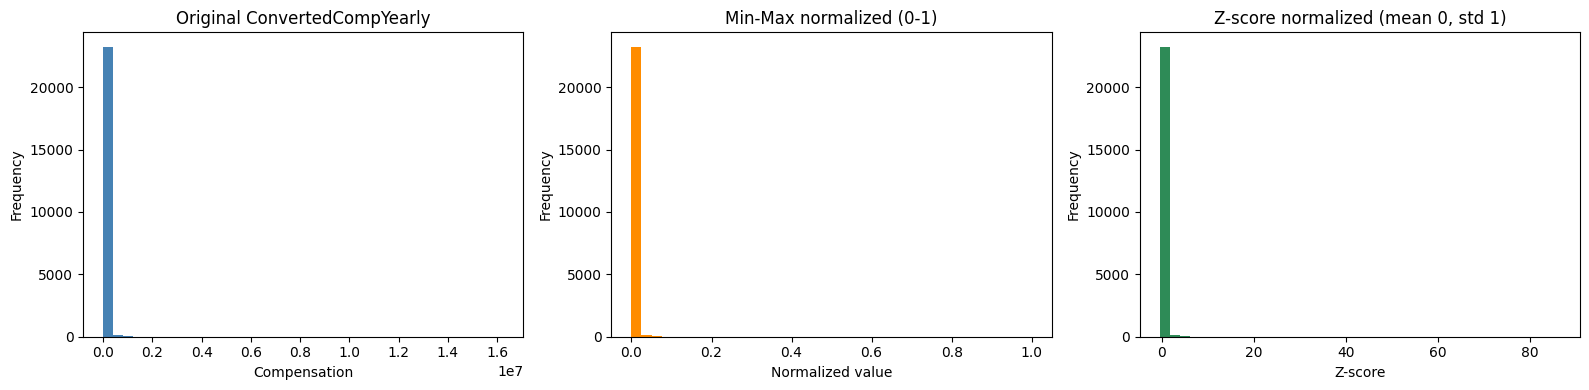

In [12]:
## Write your code here
# Visualize the distribution of the original and normalized columns
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df['ConvertedCompYearly'].dropna().plot(kind='hist', bins=40, ax=axes[0], color='steelblue')
axes[0].set_title('Original ConvertedCompYearly')
axes[0].set_xlabel('Compensation')

df['ConvertedCompYearly_MinMax'].dropna().plot(kind='hist', bins=40, ax=axes[1], color='darkorange')
axes[1].set_title('Min-Max normalized (0-1)')
axes[1].set_xlabel('Normalized value')

df['ConvertedCompYearly_Zscore'].dropna().plot(kind='hist', bins=40, ax=axes[2], color='seagreen')
axes[2].set_title('Z-score normalized (mean 0, std 1)')
axes[2].set_xlabel('Z-score')

plt.tight_layout()
plt.show()

### Summary


In this lab, you practiced essential normalization techniques, including:

- Identifying and handling duplicate rows.

- Checking for and imputing missing values.

- Applying Min-Max scaling and Z-score normalization to compensation data.

- Visualizing the impact of normalization on data distribution.


Copyright © IBM Corporation. All rights reserved.
